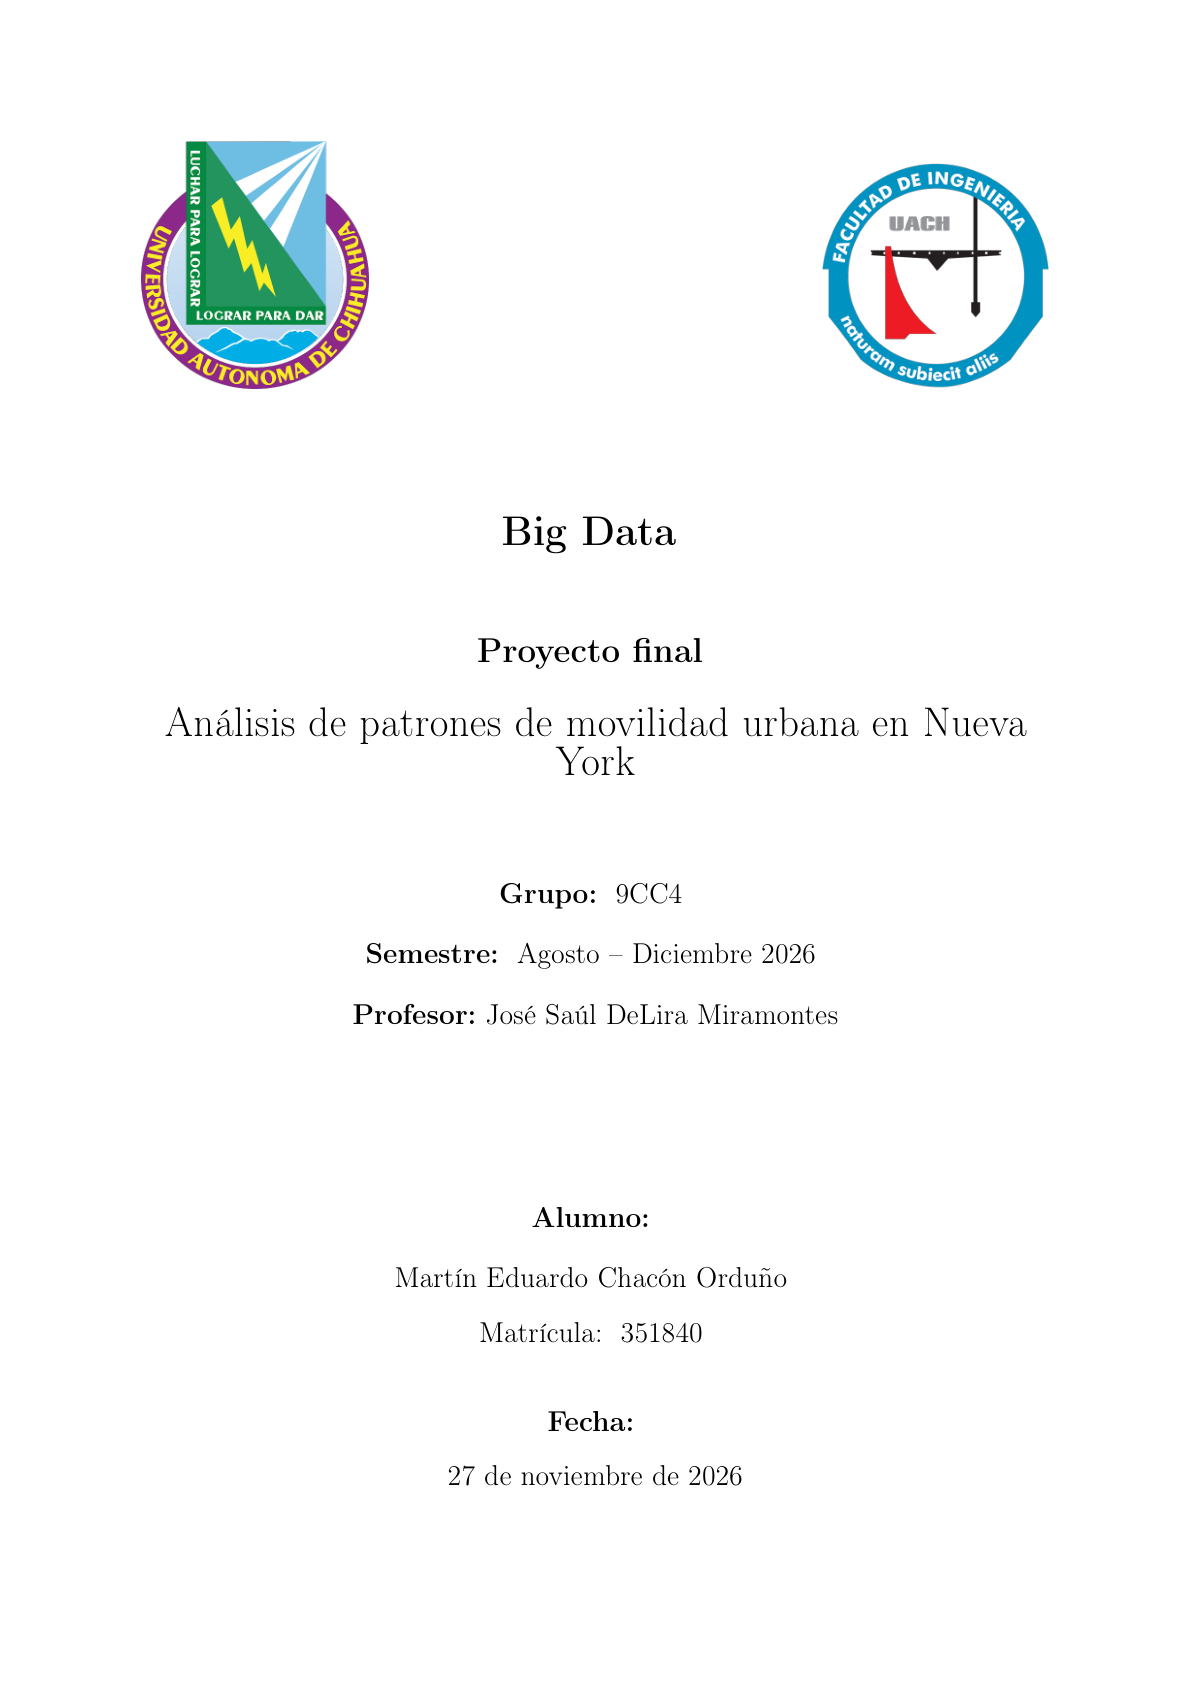

<style>
@media print {
  .jp-MarkdownCell:has(img[alt="Portada del Proyecto final de Big Data · UACH"]) {
    break-after: page;
    page-break-after: always;
  }
  img[alt="Portada del Proyecto final de Big Data · UACH"] {
    display: block;
    max-width: 100%;
    max-height: 250mm;
    width: auto;
    height: auto;
    margin: 0 auto;
  }
}
</style>

## 1. Objetivo y alcance

Identificar cuándo y dónde se concentran los viajes de Yellow Taxi en Nueva York y describir cómo varían su duración, distancia y cobro. Se analizan nueve archivos mensuales en formato Parquet publicados por la NYC Taxi & Limousine Commission (TLC). El intervalo incluye recogidas desde el 1 de enero de 2026 hasta antes del 1 de octubre de 2026, en hora local de Nueva York.

### Arquitectura y ejecución

| Tarea de Airflow | Trabajo |
|---|---|
| `ingest_tlc` | Verifica los archivos disponibles, descarga los meses faltantes y prepara el catálogo de zonas. |
| `run_spark_notebook` | Ejecuta [el notebook de análisis](01_nyc_taxi_analysis.ipynb) con Papermill. El anexo A incluye su código completo. Spark distribuye el procesamiento entre tres workers coordinados por un master, todos en Docker. |
| `publish_to_mongo` | Publica el JSON de indicadores en MongoDB. Streamlit muestra la corrida publicada más reciente y permite consultar otras corridas disponibles. |

La corrida de referencia de Airflow es `manual__2026-11-25T03:36:33.138462+00:00`. La copia de los indicadores que aparece abajo permite volver a generar las figuras y tablas de este reporte con Python y Matplotlib. Para recalcular el análisis a partir de los Parquet, se utiliza el notebook de PySpark mediante el DAG.

In [1]:
import json
from decimal import Decimal
from typing import Any

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

report: dict[str, Any] = json.loads(r'''{
    "_id": "2026-01_2026-09",
    "period_start": "2026-01-01",
    "period_end_exclusive": "2026-10-01",
    "source_months": ["2026-01","2026-02","2026-03","2026-04","2026-05","2026-06","2026-07","2026-08","2026-09"],
    "valid_trip_count": 32009526,
    "raw_trip_count": 33579399,
    "duration_limit_min": 117.08333333333333,
    "distance_limit_miles": 31.07,
    "spark_run_id": "manual__2026-11-25T03:36:33.138462+00:00",
    "indicator_count": 14,
    "zone_hour_matrix": [[16196,7431,3448,2149,1923,3078,10127,35213,56819,64706,72956,83616,94483,98789,111017,111038,103802,108256,105110,85644,79304,79333,57875,31749],[22147,8863,3672,2231,2642,3568,9213,17746,29375,39542,48157,60400,67964,74119,82141,86621,95283,109781,113327,100802,105430,104215,82618,46840],[57533,30309,11857,5968,5312,20054,31617,37037,31599,29783,32890,39618,42143,53922,76685,89896,95063,84173,75716,88172,90203,85471,84512,77921],[7264,3163,1433,888,1557,5141,18350,52219,75513,76285,75976,81922,91970,88443,94453,104524,89283,94564,89760,65845,55557,46752,28627,15156],[28525,15909,8008,5682,4687,12810,25640,36846,45101,49739,50095,55946,51217,56640,52782,52176,50230,57234,58920,59505,49396,55886,59624,45884],[15024,7127,3856,2397,2686,5222,14309,25890,37054,42951,44549,48902,51245,52060,55480,56698,63270,80581,85419,72134,71245,63367,46345,27276],[29790,15184,8651,6290,6558,6430,8914,15380,24718,31890,37620,40402,39326,39815,41331,44245,55390,61500,62571,53652,60898,91712,87534,53320],[17025,8259,2999,1686,1983,4607,9732,23498,35096,38662,41354,45454,50415,51096,53691,55740,53584,61937,65560,53687,54058,73533,72746,45125],[73578,66686,50386,34754,18797,7909,11519,16505,23094,26209,21557,21109,23069,24585,26005,26799,23808,28409,36568,42416,51519,61631,69440,72482],[18848,10227,5659,3712,3681,4963,11057,21298,32818,38709,41915,45516,48385,48604,49780,50012,50322,57872,60611,56359,54400,48617,41473,29985]],
    "quality_counts": [{"quality_status":"valid","trip_count":32009526},{"quality_status":"invalid_distance","trip_count":1087317},{"quality_status":"nonpositive_duration","trip_count":419885},{"quality_status":"duration_outlier","trip_count":32617},{"quality_status":"distance_outlier","trip_count":30017},{"quality_status":"outside_period","trip_count":37}],
    "demand_by_hour": [{"pickup_hour":0,"trip_count":1039138},{"pickup_hour":1,"trip_count":686142},{"pickup_hour":2,"trip_count":457711},{"pickup_hour":3,"trip_count":327807},{"pickup_hour":4,"trip_count":268504},{"pickup_hour":5,"trip_count":297687},{"pickup_hour":6,"trip_count":558240},{"pickup_hour":7,"trip_count":975171},{"pickup_hour":8,"trip_count":1299645},{"pickup_hour":9,"trip_count":1359968},{"pickup_hour":10,"trip_count":1379049},{"pickup_hour":11,"trip_count":1486063},{"pickup_hour":12,"trip_count":1602450},{"pickup_hour":13,"trip_count":1674532},{"pickup_hour":14,"trip_count":1822033},{"pickup_hour":15,"trip_count":1888652},{"pickup_hour":16,"trip_count":1804977},{"pickup_hour":17,"trip_count":1996433},{"pickup_hour":18,"trip_count":2070910},{"pickup_hour":19,"trip_count":1898249},{"pickup_hour":20,"trip_count":1896156},{"pickup_hour":21,"trip_count":1954602},{"pickup_hour":22,"trip_count":1815042},{"pickup_hour":23,"trip_count":1450365}],
    "demand_by_day_type": [{"day_type":"weekday","day_count":195,"trip_count":22712813,"avg_trips_per_day":116475.96},{"day_type":"weekend","day_count":78,"trip_count":9296713,"avg_trips_per_day":119188.63}],
    "top_pickup_zones": [{"location_id":237,"borough":"Manhattan","zone":"Upper East Side South","trip_count":1424062},{"location_id":161,"borough":"Manhattan","zone":"Midtown Center","trip_count":1316697},{"location_id":132,"borough":"Queens","zone":"JFK Airport","trip_count":1277454},{"location_id":236,"borough":"Manhattan","zone":"Upper East Side North","trip_count":1264645},{"location_id":186,"borough":"Manhattan","zone":"Penn Station/Madison Sq West","trip_count":988482},{"location_id":162,"borough":"Manhattan","zone":"Midtown East","trip_count":975087},{"location_id":230,"borough":"Manhattan","zone":"Times Sq/Theatre District","trip_count":923121},{"location_id":142,"borough":"Manhattan","zone":"Lincoln Square East","trip_count":921527},{"location_id":79,"borough":"Manhattan","zone":"East Village","trip_count":858834},{"location_id":170,"borough":"Manhattan","zone":"Murray Hill","trip_count":834823}],
    "top_dropoff_zones": [{"location_id":236,"borough":"Manhattan","zone":"Upper East Side North","trip_count":1305878},{"location_id":237,"borough":"Manhattan","zone":"Upper East Side South","trip_count":1279701},{"location_id":161,"borough":"Manhattan","zone":"Midtown Center","trip_count":1088082},{"location_id":170,"borough":"Manhattan","zone":"Murray Hill","trip_count":883971},{"location_id":230,"borough":"Manhattan","zone":"Times Sq/Theatre District","trip_count":873201},{"location_id":162,"borough":"Manhattan","zone":"Midtown East","trip_count":833361},{"location_id":239,"borough":"Manhattan","zone":"Upper West Side South","trip_count":824531},{"location_id":142,"borough":"Manhattan","zone":"Lincoln Square East","trip_count":816638},{"location_id":68,"borough":"Manhattan","zone":"East Chelsea","trip_count":802189},{"location_id":141,"borough":"Manhattan","zone":"Lenox Hill West","trip_count":796805}],
    "amounts_by_pickup_zone": [{"PULocationID":132,"pickup_borough":"Queens","pickup_zone":"JFK Airport","trip_count":1277454,"trips_with_total":1277454,"fare_sum_usd":{"$numberDecimal":"73958006.48"},"reported_total_usd":{"$numberDecimal":"96134222.88"},"avg_reported_total_usd":{"$numberDecimal":"75.25"},"negative_total_count":23145},{"PULocationID":138,"pickup_borough":"Queens","pickup_zone":"LaGuardia Airport","trip_count":817994,"trips_with_total":817994,"fare_sum_usd":{"$numberDecimal":"35881720.90"},"reported_total_usd":{"$numberDecimal":"56529533.34"},"avg_reported_total_usd":{"$numberDecimal":"69.11"},"negative_total_count":6904},{"PULocationID":161,"pickup_borough":"Manhattan","pickup_zone":"Midtown Center","trip_count":1316697,"trips_with_total":1316697,"fare_sum_usd":{"$numberDecimal":"23650130.62"},"reported_total_usd":{"$numberDecimal":"35850184.86"},"avg_reported_total_usd":{"$numberDecimal":"27.23"},"negative_total_count":6857},{"PULocationID":237,"pickup_borough":"Manhattan","pickup_zone":"Upper East Side South","trip_count":1424062,"trips_with_total":1424062,"fare_sum_usd":{"$numberDecimal":"19888510.05"},"reported_total_usd":{"$numberDecimal":"31202307.74"},"avg_reported_total_usd":{"$numberDecimal":"21.91"},"negative_total_count":6278},{"PULocationID":236,"pickup_borough":"Manhattan","pickup_zone":"Upper East Side North","trip_count":1264645,"trips_with_total":1264645,"fare_sum_usd":{"$numberDecimal":"18741123.88"},"reported_total_usd":{"$numberDecimal":"28590772.15"},"avg_reported_total_usd":{"$numberDecimal":"22.61"},"negative_total_count":4290}],
    "amounts_by_weekday": [{"iso_weekday":1,"trip_count":3781386,"trips_with_total":3781386,"fare_sum_usd":{"$numberDecimal":"80442865.56"},"reported_total_usd":{"$numberDecimal":"115866955.46"},"avg_reported_total_usd":{"$numberDecimal":"30.64"},"negative_total_count":19435},{"iso_weekday":2,"trip_count":4437017,"trips_with_total":4437017,"fare_sum_usd":{"$numberDecimal":"92845869.15"},"reported_total_usd":{"$numberDecimal":"133822221.28"},"avg_reported_total_usd":{"$numberDecimal":"30.16"},"negative_total_count":21824},{"iso_weekday":3,"trip_count":4732986,"trips_with_total":4732986,"fare_sum_usd":{"$numberDecimal":"99533142.40"},"reported_total_usd":{"$numberDecimal":"143253670.28"},"avg_reported_total_usd":{"$numberDecimal":"30.27"},"negative_total_count":22734},{"iso_weekday":4,"trip_count":5004777,"trips_with_total":5004777,"fare_sum_usd":{"$numberDecimal":"107068956.82"},"reported_total_usd":{"$numberDecimal":"153112495.38"},"avg_reported_total_usd":{"$numberDecimal":"30.59"},"negative_total_count":24430},{"iso_weekday":5,"trip_count":4756647,"trips_with_total":4756647,"fare_sum_usd":{"$numberDecimal":"99493632.68"},"reported_total_usd":{"$numberDecimal":"142060116.55"},"avg_reported_total_usd":{"$numberDecimal":"29.87"},"negative_total_count":24755},{"iso_weekday":6,"trip_count":5060864,"trips_with_total":5060864,"fare_sum_usd":{"$numberDecimal":"104540829.79"},"reported_total_usd":{"$numberDecimal":"144666837.78"},"avg_reported_total_usd":{"$numberDecimal":"28.59"},"negative_total_count":24855},{"iso_weekday":7,"trip_count":4235849,"trips_with_total":4235849,"fare_sum_usd":{"$numberDecimal":"91500572.39"},"reported_total_usd":{"$numberDecimal":"126925874.42"},"avg_reported_total_usd":{"$numberDecimal":"29.96"},"negative_total_count":20474}],
    "amounts_by_payment": [{"payment_type":1,"payment_method":"Credit card","trip_count":20687096,"trips_with_total":20687096,"fare_sum_usd":{"$numberDecimal":"405023361.24"},"reported_total_usd":{"$numberDecimal":"618767874.77"},"avg_reported_total_usd":{"$numberDecimal":"29.91"},"negative_total_count":2310},{"payment_type":0,"payment_method":"Flex Fare","trip_count":8117755,"trips_with_total":8117755,"fare_sum_usd":{"$numberDecimal":"212895671.53"},"reported_total_usd":{"$numberDecimal":"266783711.33"},"avg_reported_total_usd":{"$numberDecimal":"32.86"},"negative_total_count":116},{"payment_type":2,"payment_method":"Cash","trip_count":2894882,"trips_with_total":2894882,"fare_sum_usd":{"$numberDecimal":"56220766.36"},"reported_total_usd":{"$numberDecimal":"72448431.23"},"avg_reported_total_usd":{"$numberDecimal":"25.03"},"negative_total_count":38764},{"payment_type":4,"payment_method":"Dispute","trip_count":231346,"trips_with_total":231346,"fare_sum_usd":{"$numberDecimal":"504951.39"},"reported_total_usd":{"$numberDecimal":"663445.89"},"avg_reported_total_usd":{"$numberDecimal":"2.87"},"negative_total_count":101713},{"payment_type":3,"payment_method":"No charge","trip_count":78444,"trips_with_total":78444,"fare_sum_usd":{"$numberDecimal":"781023.37"},"reported_total_usd":{"$numberDecimal":"1044581.32"},"avg_reported_total_usd":{"$numberDecimal":"13.32"},"negative_total_count":15604},{"payment_type":5,"payment_method":"Unknown","trip_count":3,"trips_with_total":3,"fare_sum_usd":{"$numberDecimal":"94.90"},"reported_total_usd":{"$numberDecimal":"126.61"},"avg_reported_total_usd":{"$numberDecimal":"42.20"},"negative_total_count":0}],
    "trip_metrics_by_hour": [{"pickup_hour":0,"trip_count":1039138,"avg_duration_min":15.75,"median_duration_min":13.93,"trips_with_distance":1039138,"avg_distance_km":6.61,"median_distance_km":4.25},{"pickup_hour":1,"trip_count":686142,"avg_duration_min":14.88,"median_duration_min":13.25,"trips_with_distance":686142,"avg_distance_km":6.28,"median_distance_km":4.18},{"pickup_hour":2,"trip_count":457711,"avg_duration_min":14.26,"median_duration_min":12.87,"trips_with_distance":457711,"avg_distance_km":6.17,"median_distance_km":4.31},{"pickup_hour":3,"trip_count":327807,"avg_duration_min":14.36,"median_duration_min":12.87,"trips_with_distance":327807,"avg_distance_km":6.68,"median_distance_km":4.67},{"pickup_hour":4,"trip_count":268504,"avg_duration_min":15.74,"median_duration_min":13.77,"trips_with_distance":268504,"avg_distance_km":8.26,"median_distance_km":5.75},{"pickup_hour":5,"trip_count":297687,"avg_duration_min":17.57,"median_duration_min":13.65,"trips_with_distance":297687,"avg_distance_km":9.29,"median_distance_km":6.04},{"pickup_hour":6,"trip_count":558240,"avg_duration_min":17.72,"median_duration_min":12.92,"trips_with_distance":558240,"avg_distance_km":7.91,"median_distance_km":4.73},{"pickup_hour":7,"trip_count":975171,"avg_duration_min":17.72,"median_duration_min":13.15,"trips_with_distance":975171,"avg_distance_km":6.35,"median_distance_km":3.7},{"pickup_hour":8,"trip_count":1299645,"avg_duration_min":17.98,"median_duration_min":14.18,"trips_with_distance":1299645,"avg_distance_km":5.54,"median_distance_km":3.22},{"pickup_hour":9,"trip_count":1359968,"avg_duration_min":17.75,"median_duration_min":14.22,"trips_with_distance":1359968,"avg_distance_km":5.25,"median_distance_km":2.96},{"pickup_hour":10,"trip_count":1379049,"avg_duration_min":17.93,"median_duration_min":14.38,"trips_with_distance":1379049,"avg_distance_km":5.19,"median_distance_km":2.86},{"pickup_hour":11,"trip_count":1486063,"avg_duration_min":18.48,"median_duration_min":14.88,"trips_with_distance":1486063,"avg_distance_km":5.19,"median_distance_km":2.77},{"pickup_hour":12,"trip_count":1602450,"avg_duration_min":18.54,"median_duration_min":14.87,"trips_with_distance":1602450,"avg_distance_km":5.16,"median_distance_km":2.74},{"pickup_hour":13,"trip_count":1674532,"avg_duration_min":19.02,"median_duration_min":15.05,"trips_with_distance":1674532,"avg_distance_km":5.34,"median_distance_km":2.8},{"pickup_hour":14,"trip_count":1822033,"avg_duration_min":20.04,"median_duration_min":15.37,"trips_with_distance":1822033,"avg_distance_km":5.61,"median_distance_km":2.86},{"pickup_hour":15,"trip_count":1888652,"avg_duration_min":20.41,"median_duration_min":15.43,"trips_with_distance":1888652,"avg_distance_km":5.48,"median_distance_km":2.78},{"pickup_hour":16,"trip_count":1804977,"avg_duration_min":20.05,"median_duration_min":14.92,"trips_with_distance":1804977,"avg_distance_km":5.47,"median_distance_km":2.74},{"pickup_hour":17,"trip_count":1996433,"avg_duration_min":18.64,"median_duration_min":14.45,"trips_with_distance":1996433,"avg_distance_km":4.99,"median_distance_km":2.66},{"pickup_hour":18,"trip_count":2070910,"avg_duration_min":16.81,"median_duration_min":13.6,"trips_with_distance":2070910,"avg_distance_km":4.73,"median_distance_km":2.62},{"pickup_hour":19,"trip_count":1898249,"avg_duration_min":16.37,"median_duration_min":13.5,"trips_with_distance":1898249,"avg_distance_km":5.08,"median_distance_km":2.78},{"pickup_hour":20,"trip_count":1896156,"avg_duration_min":16.1,"median_duration_min":13.77,"trips_with_distance":1896156,"avg_distance_km":5.57,"median_distance_km":3.27},{"pickup_hour":21,"trip_count":1954602,"avg_duration_min":16.06,"median_duration_min":13.95,"trips_with_distance":1954602,"avg_distance_km":5.66,"median_distance_km":3.46},{"pickup_hour":22,"trip_count":1815042,"avg_duration_min":16.39,"median_duration_min":14.3,"trips_with_distance":1815042,"avg_distance_km":5.97,"median_distance_km":3.7},{"pickup_hour":23,"trip_count":1450365,"avg_duration_min":16.43,"median_duration_min":14.35,"trips_with_distance":1450365,"avg_distance_km":6.49,"median_distance_km":4.06}],
    "airport_pickup_metrics": [{"PULocationID":132,"pickup_borough":"Queens","pickup_zone":"JFK Airport","trip_count":1277454,"avg_duration_min":40.59,"median_duration_min":40.02,"trips_with_distance":1277454,"avg_distance_km":23.56,"median_distance_km":27.09},{"PULocationID":138,"pickup_borough":"Queens","pickup_zone":"LaGuardia Airport","trip_count":817994,"avg_duration_min":32.04,"median_duration_min":29.55,"trips_with_distance":817994,"avg_distance_km":15.33,"median_distance_km":15.06},{"PULocationID":1,"pickup_borough":"EWR","pickup_zone":"Newark Airport","trip_count":1011,"avg_duration_min":3.9,"median_duration_min":0.15,"trips_with_distance":1011,"avg_distance_km":2.54,"median_distance_km":0.08}],
    "trips_by_pickup_month": [{"pickup_month":"2026-01","trip_count":3547527},{"pickup_month":"2026-02","trip_count":3230038},{"pickup_month":"2026-03","trip_count":3775530},{"pickup_month":"2026-04","trip_count":3680617},{"pickup_month":"2026-05","trip_count":3917229},{"pickup_month":"2026-06","trip_count":3655464},{"pickup_month":"2026-07","trip_count":3354890},{"pickup_month":"2026-08","trip_count":3172588},{"pickup_month":"2026-09","trip_count":3675643}]
}''')

In [2]:
def number(value: int | float | Decimal, digits: int = 0) -> str:
    return f"{value:,.{digits}f}".translate(str.maketrans({",": " ", ".": ","}))


def usd(value: dict[str, str]) -> Decimal:
    return Decimal(value["$numberDecimal"])


def table(headers: tuple[str, ...], rows: list[tuple[str, ...]]) -> None:
    lines: list[str] = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    lines.extend("| " + " | ".join(row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


def style_axis(axis: plt.Axes, ylabel: str) -> None:
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", color="#dbe5ec", linewidth=0.7)
    axis.set_axisbelow(True)
    for spine in axis.spines.values():
        spine.set_visible(False)
    axis.tick_params(length=0, pad=5)


blue: str = "#167891"
amber: str = "#a75a08"
raw: int = report["raw_trip_count"]
valid: int = report["valid_trip_count"]
months: list[str] = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep"]
plt.rcParams.update({"figure.dpi": 155, "font.size": 10, "axes.titleweight": "bold"})
display(Markdown(
    f"**{number(valid)} viajes válidos** de **{number(raw)} registros de origen**. "
    f"La corrida generó **{report['indicator_count']} tablas de indicadores**."
))

**32 009 526 viajes válidos** de **33 579 399 registros de origen**. La corrida generó **14 tablas de indicadores**.

## 2. Limpieza y control de calidad

Se normalizaron las columnas utilizadas por Spark y se validaron las fechas de recogida, la duración y la distancia. Para detectar valores extremos se estimó el percentil 99,9 aproximado en los registros elegibles. Cada viaje excluido se cuenta una sola vez, bajo la primera regla aplicable.

Se incorporó el catálogo de zonas mediante dos uniones izquierdas, una para la recogida y otra para la llegada. Así se conservan los viajes válidos cuyo identificador queda sin correspondencia. El análisis conservó **32 009 526** viajes antes y después de las uniones.

In [3]:
quality: list[dict[str, Any]] = report["quality_counts"]
quality_labels: dict[str, str] = {
    "valid": "Viaje válido",
    "invalid_distance": "Distancia inválida o no positiva",
    "nonpositive_duration": "Duración no positiva",
    "duration_outlier": "Duración sobre el límite",
    "distance_outlier": "Distancia sobre el límite",
    "outside_period": "Recogida fuera del periodo",
}
assert sum(row["trip_count"] for row in quality) == raw
assert next(row["trip_count"] for row in quality if row["quality_status"] == "valid") == valid
for indicator in ("demand_by_hour", "demand_by_day_type", "trips_by_pickup_month",
                  "amounts_by_payment", "amounts_by_weekday"):
    assert sum(row["trip_count"] for row in report[indicator]) == valid, indicator

table(
    ("Resultado", "Registros", "% del origen"),
    [(quality_labels[row["quality_status"]], number(row["trip_count"]),
      number(row["trip_count"] * 100 / raw, 2) + " %") for row in quality],
)
display(Markdown(
    f"Se excluyeron **{number(raw - valid)} registros**. Los límites estimados fueron "
    f"**{number(report['duration_limit_min'], 2)} minutos** y "
    f"**{number(report['distance_limit_miles'], 2)} millas**."
))

| Resultado | Registros | % del origen |
| --- | --- | --- |
| Viaje válido | 32 009 526 | 95,32 % |
| Distancia inválida o no positiva | 1 087 317 | 3,24 % |
| Duración no positiva | 419 885 | 1,25 % |
| Duración sobre el límite | 32 617 | 0,10 % |
| Distancia sobre el límite | 30 017 | 0,09 % |
| Recogida fuera del periodo | 37 | 0,00 % |

Se excluyeron **1 569 873 registros**. Los límites estimados fueron **117,08 minutos** y **31,07 millas**.

## 3. Demanda por hora, mes y tipo de día

La hora de recogida se interpreta en horario local. La comparación entre tipos de día usa viajes por día para considerar que el periodo tiene distinta cantidad de días entre semana y fines de semana.

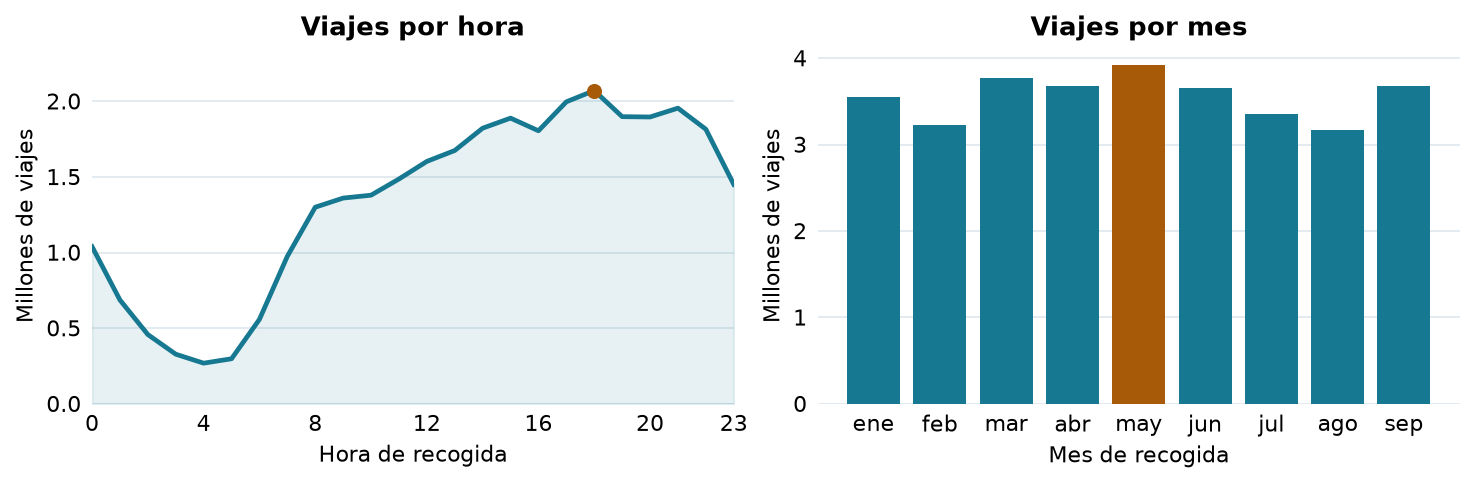

| Tipo de día | Días | Viajes | Viajes por día |
| --- | --- | --- | --- |
| Lunes a viernes | 195 | 22 712 813 | 116 475,96 |
| Sábado y domingo | 78 | 9 296 713 | 119 188,63 |

Las **18:00** concentraron **2 070 910 viajes**. **Mayo** registró el mayor total mensual, con **3 917 229 viajes**. El fin de semana registró **2,33 % más viajes por día**.

In [4]:
hourly: list[dict[str, Any]] = sorted(report["demand_by_hour"], key=lambda row: row["pickup_hour"])
monthly: list[dict[str, Any]] = sorted(report["trips_by_pickup_month"], key=lambda row: row["pickup_month"])
peak: dict[str, Any] = max(hourly, key=lambda row: row["trip_count"])
peak_month: dict[str, Any] = max(monthly, key=lambda row: row["trip_count"])
hours: list[int] = [row["pickup_hour"] for row in hourly]
hour_totals: list[float] = [row["trip_count"] / 1_000_000 for row in hourly]
month_totals: list[float] = [row["trip_count"] / 1_000_000 for row in monthly]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(9.4, 3.0), layout="constrained")
ax.plot(hours, hour_totals, color=blue, linewidth=2.2)
ax.fill_between(hours, hour_totals, color=blue, alpha=0.1)
ax.scatter(peak["pickup_hour"], peak["trip_count"] / 1_000_000, color=amber, zorder=3)
ax.set(title="Viajes por hora", xlabel="Hora de recogida", xlim=(0, 23), ylim=(0, 2.35),
       xticks=[0, 4, 8, 12, 16, 20, 23])
bx.bar(months, month_totals, color=[amber if total == max(month_totals) else blue
                                  for total in month_totals])
bx.set(title="Viajes por mes", xlabel="Mes de recogida")
for axis in (ax, bx):
    style_axis(axis, "Millones de viajes")
plt.show()
plt.close(fig)

by_day: dict[str, dict[str, Any]] = {row["day_type"]: row for row in report["demand_by_day_type"]}
table(("Tipo de día", "Días", "Viajes", "Viajes por día"), [
    (label, number(by_day[key]["day_count"]), number(by_day[key]["trip_count"]),
     number(by_day[key]["avg_trips_per_day"], 2))
    for key, label in (("weekday", "Lunes a viernes"), ("weekend", "Sábado y domingo"))
])
increase: float = 100 * (by_day["weekend"]["avg_trips_per_day"] /
                         by_day["weekday"]["avg_trips_per_day"] - 1)
display(Markdown(
    f"Las **{peak['pickup_hour']:02d}:00** concentraron **{number(peak['trip_count'])} viajes**. "
    f"**Mayo** registró el mayor total mensual, con **{number(peak_month['trip_count'])} viajes**. "
    f"El fin de semana registró **{number(increase, 2)} % más viajes por día**."
))

## 4. Zonas con mayor actividad

El mapa muestra la demanda por hora de las diez zonas con más recogidas. El ranking de llegadas se calcula de forma independiente.

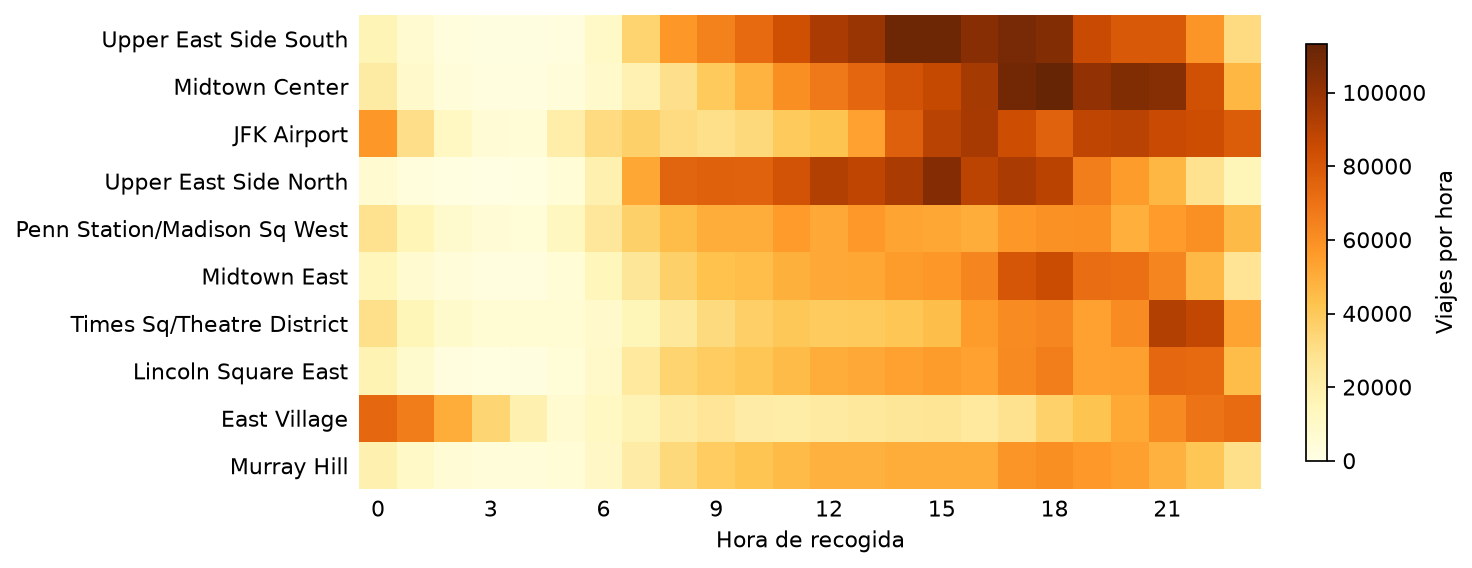

| Zona de recogida | Viajes | Zona de llegada | Viajes |
| --- | --- | --- | --- |
| Upper East Side South | 1 424 062 | Upper East Side North | 1 305 878 |
| Midtown Center | 1 316 697 | Upper East Side South | 1 279 701 |
| JFK Airport | 1 277 454 | Midtown Center | 1 088 082 |
| Upper East Side North | 1 264 645 | Murray Hill | 883 971 |
| Penn Station/Madison Sq West | 988 482 | Times Sq/Theatre District | 873 201 |
| Midtown East | 975 087 | Midtown East | 833 361 |
| Times Sq/Theatre District | 923 121 | Upper West Side South | 824 531 |
| Lincoln Square East | 921 527 | Lincoln Square East | 816 638 |
| East Village | 858 834 | East Chelsea | 802 189 |
| Murray Hill | 834 823 | Lenox Hill West | 796 805 |

In [5]:
pickups: list[dict[str, Any]] = report["top_pickup_zones"]
dropoffs: list[dict[str, Any]] = report["top_dropoff_zones"]
fig, ax = plt.subplots(figsize=(9.4, 3.55), layout="constrained")
image = ax.imshow(report["zone_hour_matrix"], aspect="auto", cmap="YlOrBr",
                  interpolation="nearest", vmin=0)
ax.set_xticks(list(range(0, 24, 3)))
ax.set_yticks(range(len(pickups)), [row["zone"] for row in pickups])
ax.set_xlabel("Hora de recogida")
ax.tick_params(length=0, pad=5)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(image, ax=ax, label="Viajes por hora", shrink=0.88)
plt.show()
plt.close(fig)

table(("Zona de recogida", "Viajes", "Zona de llegada", "Viajes"), [
    (pickup["zone"], number(pickup["trip_count"]), dropoff["zone"], number(dropoff["trip_count"]))
    for pickup, dropoff in zip(pickups, dropoffs, strict=True)
])

Upper East Side South lideró las recogidas y Upper East Side North las llegadas. JFK fue la tercera zona por volumen de recogidas.

## 5. Cobros reportados

El indicador suma `total_amount` sobre los viajes válidos y conserva los importes negativos reportados. El diccionario de TLC especifica que el total excluye las propinas pagadas en efectivo.

In [6]:
payments: list[dict[str, Any]] = report["amounts_by_payment"]
total_usd: Decimal = sum((usd(row["reported_total_usd"]) for row in payments), Decimal(0))
card: dict[str, Any] = next(row for row in payments if row["payment_method"] == "Credit card")
display(Markdown(
    f"El cobro reportado sumó **{number(total_usd, 2)} USD**. "
    f"Tarjeta aportó **{number(100 * usd(card['reported_total_usd']) / total_usd, 2)} %** "
    "del total y fue el método más frecuente."
))
payment_labels: dict[str, str] = {
    "Credit card": "Tarjeta", "Cash": "Efectivo", "Dispute": "En disputa",
    "No charge": "Sin cargo", "Unknown": "Desconocido",
}
table(("Tipo de pago", "Viajes", "Total (USD)", "Promedio (USD)"), [
    (payment_labels.get(row["payment_method"], row["payment_method"]), number(row["trip_count"]),
     number(usd(row["reported_total_usd"]), 2), number(usd(row["avg_reported_total_usd"]), 2))
    for row in payments
])

El cobro reportado sumó **959 708 171,15 USD**. Tarjeta aportó **64,47 %** del total y fue el método más frecuente.

| Tipo de pago | Viajes | Total (USD) | Promedio (USD) |
| --- | --- | --- | --- |
| Tarjeta | 20 687 096 | 618 767 874,77 | 29,91 |
| Flex Fare | 8 117 755 | 266 783 711,33 | 32,86 |
| Efectivo | 2 894 882 | 72 448 431,23 | 25,03 |
| En disputa | 231 346 | 663 445,89 | 2,87 |
| Sin cargo | 78 444 | 1 044 581,32 | 13,32 |
| Desconocido | 3 | 126,61 | 42,20 |

In [7]:
day_names: tuple[str, ...] = ("Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo")
table(("Día de recogida", "Total (USD)"), [
    (day_names[row["iso_weekday"] - 1], number(usd(row["reported_total_usd"]), 2))
    for row in report["amounts_by_weekday"]
])
table(("Cinco zonas con mayor cobro de origen", "Total (USD)"), [
    (row["pickup_zone"], number(usd(row["reported_total_usd"]), 2))
    for row in report["amounts_by_pickup_zone"]
])

| Día de recogida | Total (USD) |
| --- | --- |
| Lunes | 115 866 955,46 |
| Martes | 133 822 221,28 |
| Miércoles | 143 253 670,28 |
| Jueves | 153 112 495,38 |
| Viernes | 142 060 116,55 |
| Sábado | 144 666 837,78 |
| Domingo | 126 925 874,42 |

| Cinco zonas con mayor cobro de origen | Total (USD) |
| --- | --- |
| JFK Airport | 96 134 222,88 |
| LaGuardia Airport | 56 529 533,34 |
| Midtown Center | 35 850 184,86 |
| Upper East Side South | 31 202 307,74 |
| Upper East Side North | 28 590 772,15 |

## 6. Duración y distancia de los viajes

La gráfica presenta medias y medianas por hora de recogida. La tabla de aeropuertos incluye solo viajes que salen de las zonas correspondientes a JFK, LaGuardia y Newark.

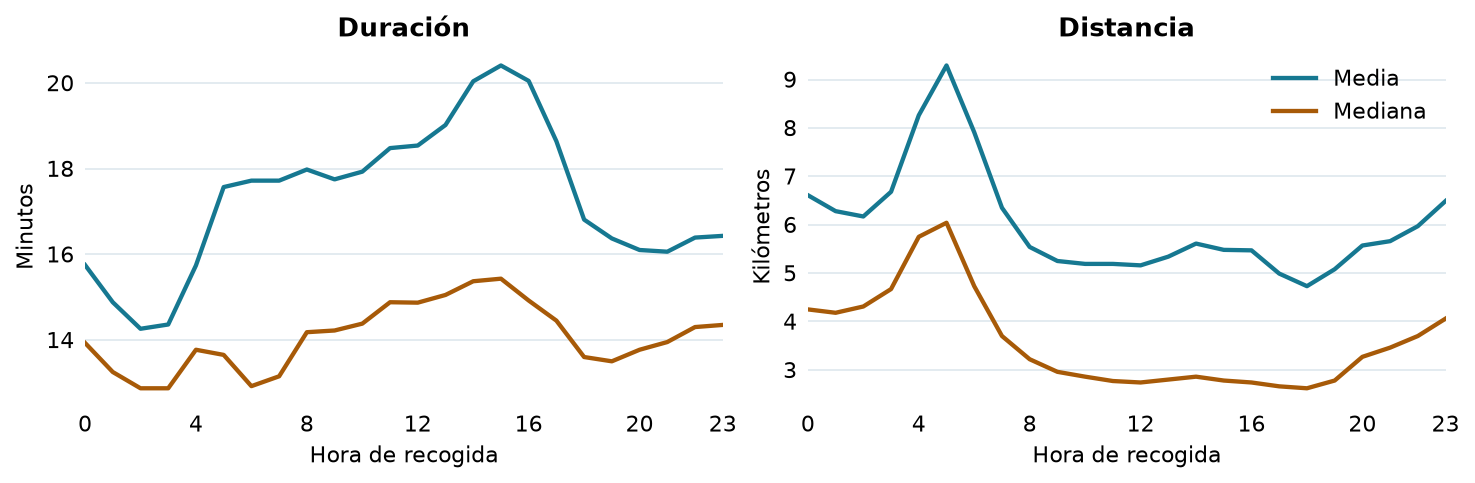

| Aeropuerto | Viajes | Media (min) | Mediana (min) | Media (km) |
| --- | --- | --- | --- | --- |
| JFK Airport | 1 277 454 | 40,59 | 40,02 | 23,56 |
| LaGuardia Airport | 817 994 | 32,04 | 29,55 | 15,33 |
| Newark Airport | 1 011 | 3,90 | 0,15 | 2,54 |

In [8]:
metrics: list[dict[str, Any]] = sorted(report["trip_metrics_by_hour"], key=lambda row: row["pickup_hour"])
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.0), layout="constrained")
for axis, title, unit, avg_key, median_key in (
    (axes[0], "Duración", "Minutos", "avg_duration_min", "median_duration_min"),
    (axes[1], "Distancia", "Kilómetros", "avg_distance_km", "median_distance_km"),
):
    axis.plot(hours, [row[avg_key] for row in metrics], color=blue, label="Media", linewidth=2)
    axis.plot(hours, [row[median_key] for row in metrics], color=amber, label="Mediana", linewidth=2)
    axis.set(title=title, xlabel="Hora de recogida", xlim=(0, 23), xticks=[0, 4, 8, 12, 16, 20, 23])
    style_axis(axis, unit)
axes[1].legend(frameon=False)
plt.show()
plt.close(fig)

table(("Aeropuerto", "Viajes", "Media (min)", "Mediana (min)", "Media (km)"), [
    (row["pickup_zone"], number(row["trip_count"]), number(row["avg_duration_min"], 2),
     number(row["median_duration_min"], 2), number(row["avg_distance_km"], 2))
    for row in report["airport_pickup_metrics"]
])

Las salidas de JFK tuvieron mayor duración y distancia medias que las de LaGuardia. Newark tuvo un volumen menor y una mediana de duración de **0,15 minutos**. Esa cifra requiere revisar los registros de Newark antes de usarla para estimar tiempos de traslado.

## 7. Conclusiones

- **Hora de mayor demanda.** Las 18:00 concentraron el mayor volumen de recogidas. El promedio diario fue mayor en fines de semana, por lo que conviene distinguir el tipo de día al interpretar los horarios.
- **Volumen y cobros por zona.** Upper East Side South lideró las recogidas y Upper East Side North las llegadas. JFK encabezó el cobro total reportado por zona de recogida, con **96 134 222,88 USD**.
- **Alcance.** Los resultados describen los viajes válidos de Yellow Taxi registrados de enero a septiembre de 2026. Los umbrales de limpieza se estiman sobre los datos de cada corrida y pueden cambiar al ampliar el periodo.

## 8. Fuentes



- [NYC Taxi & Limousine Commission · TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)
- [NYC TLC · Diccionario de datos de Yellow Taxi](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)
- [Apache Spark · Documentación 4.0.1](https://spark.apache.org/docs/4.0.1/)
- [Apache Airflow · Documentación 3.3.2](https://airflow.apache.org/docs/apache-airflow/3.3.2/)

### Evidencia del clúster

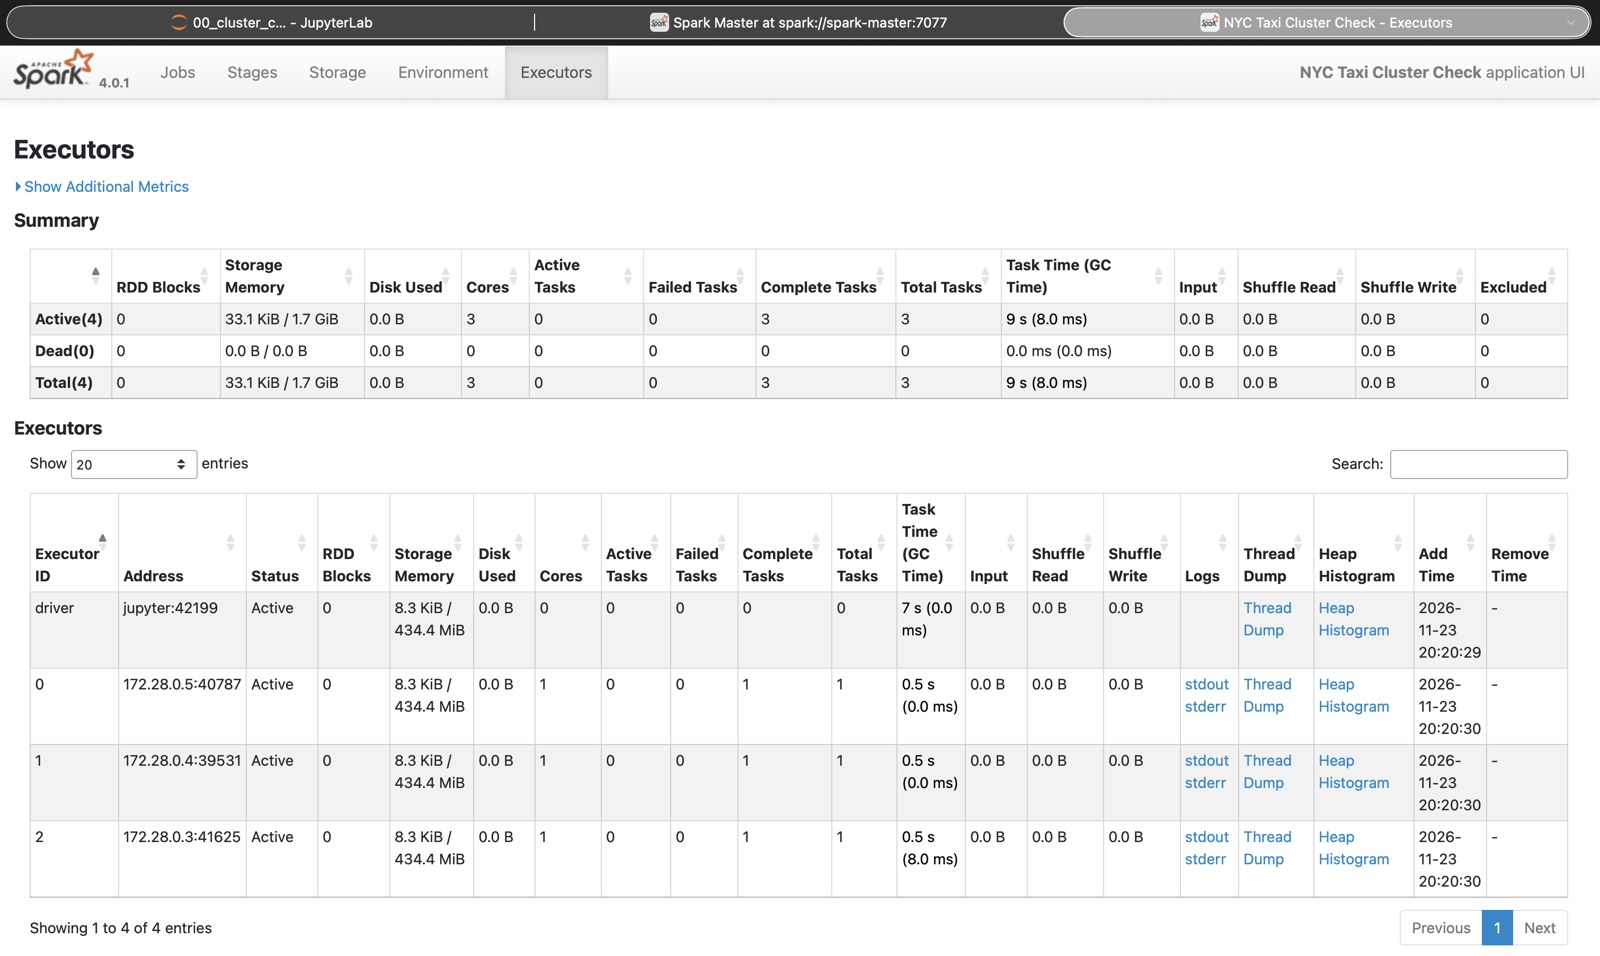

Vista de ejecutores de Spark en la prueba del clúster. La corrida del reporte se identifica por su ID de Airflow.

## Anexo A. Notebook de análisis con PySpark

Archivo fuente: [`01_nyc_taxi_analysis.ipynb`](01_nyc_taxi_analysis.ipynb). Airflow ejecuta este notebook con Papermill para calcular los indicadores del reporte.

El anexo presenta la documentación y las 12 celdas de Python del archivo en su orden original. Los bloques se muestran como parte del documento. Para ejecutar PySpark, abre el archivo fuente.

Este proyecto analiza los viajes de Yellow Taxi en un periodo configurable
para identificar patrones de demanda por horario y zona,
comparar los días de lunes a viernes con los fines de semana y
describir los cobros, las distancias y las duraciones de los viajes.

### A.1 Carga e inspección de los datos

Se carga un Parquet por cada mes del periodo, incluyendo el mes inicial y
el final. La ejecución predeterminada cubre enero a septiembre de 2026. Se revisan el esquema,
el número de registros y el rango de fechas de recogida por archivo.
También se carga el catálogo de zonas de la TLC para identificar
los orígenes y destinos de los viajes.

**Fuentes**

- [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)
- [Diccionario de datos de Yellow Taxi](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

**Celda 1**

```python
import os
from pyspark.sql import DataFrame, SparkSession, functions as F
from pyspark.sql.types import IntegerType, StringType, StructField, StructType

spark: SparkSession = (
    SparkSession.builder
    .appName("NYC Yellow Taxi Mobility")
    .master("spark://spark-master:7077")
    .config("spark.driver.host", os.environ.get("SPARK_DRIVER_HOST", "jupyter"))
    .config("spark.driver.bindAddress", "0.0.0.0")
    .config("spark.ui.showConsoleProgress", os.environ.get("SPARK_CONSOLE_PROGRESS", "true"))
    .config("spark.executor.cores", "2")
    .config("spark.executor.memory", "3g")
    .config("spark.cores.max", "6")
    .config("spark.dynamicAllocation.enabled", "false")
    .config("spark.sql.session.timeZone", "America/New_York")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")
print(f"Spark {spark.version} | Master: {spark.sparkContext.master}")
```

**Celda 2**

```python
from pathlib import Path

from src.tlc_period import configured_months, month_range

start_month, end_month = configured_months()
first_pickup_day, end_exclusive, source_months = month_range(start_month, end_month)

period_start: str = f"{first_pickup_day.isoformat()} 00:00:00"
period_end: str = f"{end_exclusive.isoformat()} 00:00:00"

raw_dir: Path = Path("/workspace/data/raw")
trip_paths: dict[str, Path] = {
    month: raw_dir / f"yellow_tripdata_{month}.parquet"
    for month in source_months
}

missing_files: list[str] = [
    path.name for path in trip_paths.values() if not path.is_file()
]
if missing_files:
    raise FileNotFoundError(f"Missing monthly files: {', '.join(missing_files)}")

trip_column_types: dict[str, str] = {
    "tpep_pickup_datetime": "timestamp_ntz",
    "tpep_dropoff_datetime": "timestamp_ntz",
    "PULocationID": "int",
    "DOLocationID": "int",
    "payment_type": "bigint",
    "trip_distance": "double",
    "fare_amount": "double",
    "total_amount": "double",
}


def read_monthly_trips(month: str, path: Path) -> DataFrame:
    monthly_trips: DataFrame = spark.read.parquet(str(path))
    missing_columns: set[str] = set(trip_column_types) - set(monthly_trips.columns)
    if missing_columns:
        raise ValueError(f"{path.name} is missing columns: {sorted(missing_columns)}")

    return monthly_trips.select(
        F.lit(month).alias("source_month"),
        *[
            F.col(column).cast(sql_type).alias(column)
            for column, sql_type in trip_column_types.items()
        ],
    )


monthly_frames: list[DataFrame] = [
    read_monthly_trips(month, path) for month, path in trip_paths.items()
]

trips_raw: DataFrame = monthly_frames[0]
for monthly_trips in monthly_frames[1:]:
    trips_raw = trips_raw.unionByName(monthly_trips)

zone_schema: StructType = StructType([
    StructField("LocationID", IntegerType()),
    StructField("Borough", StringType()),
    StructField("Zone", StringType()),
    StructField("service_zone", StringType()),
])

zones: DataFrame = (
    spark.read
    .option("header", True)
    .option("enforceSchema", False)
    .option("mode", "FAILFAST")
    .schema(zone_schema)
    .csv(str(raw_dir / "taxi_zone_lookup.csv"))
)

trip_profile: DataFrame = (
    trips_raw.groupBy("source_month")
    .agg(
        F.count("*").alias("raw_trip_count"),
        F.min("tpep_pickup_datetime").alias("earliest_pickup"),
        F.max("tpep_pickup_datetime").alias("latest_pickup"),
    )
    .orderBy("source_month")
)

print(f"Pickup period: {period_start} through {period_end} (exclusive)")
trips_raw.printSchema()
trip_profile.show(len(source_months), truncate=False)
print(f"Zone catalog rows: {zones.count():,}")
```

### A.2 Limpieza y preparación de los viajes

El periodo se define por la fecha de recogida. Se incluyen los viajes
que comenzaron desde el primer día del mes inicial a las 00:00 hasta
antes de las 00:00 del primer día posterior al mes final.

Cada registro recibe un estado de calidad. Se excluyen las recogidas
fuera del periodo, las fechas faltantes, las duraciones no positivas,
las distancias faltantes o inválidas y las tarifas que no se pueden
representar como un importe decimal.

Entre los viajes que pasan esos filtros, se calcula el percentil 99.9
de duración y distancia. Los viajes que superan cualquiera de esos
límites se excluyen de la base analítica. Si un viaje cumple varias
condiciones de exclusión, se contabiliza bajo la primera.

Para los viajes aceptados se calcula la hora de recogida, el día de la
semana, la duración en minutos y la distancia en kilómetros.

**Celda 3**

```python
from pyspark.sql import Column, Row

start_at: Column = F.lit(period_start).cast("timestamp_ntz")
end_at: Column = F.lit(period_end).cast("timestamp_ntz")
pickup_at: Column = F.col("tpep_pickup_datetime")
dropoff_at: Column = F.col("tpep_dropoff_datetime")
distance_miles: Column = F.col("trip_distance")
fare_for_quality: Column = F.col("fare_amount").try_cast("decimal(18,2)")

duration_for_quality: Column = (
    F.timestamp_diff("MICROSECOND", pickup_at, dropoff_at) / 60_000_000
)

initial_status: Column = (
    F.when(pickup_at.isNull(), "missing_pickup")
    .when((pickup_at < start_at) | (pickup_at >= end_at), "outside_period")
    .when(dropoff_at.isNull(), "missing_dropoff")
    .when(dropoff_at <= pickup_at, "nonpositive_duration")
    .when(distance_miles.isNull(), "missing_distance")
    .when(
        F.isnan(distance_miles)
        | (distance_miles <= 0)
        | (distance_miles >= F.lit(float("inf"))),
        "invalid_distance",
    )
    .when(fare_for_quality.isNull(), "missing_or_invalid_fare")
    .otherwise("valid")
)

trips_screened: DataFrame = trips_raw.withColumn("quality_status", initial_status)
eligible_trips: DataFrame = trips_screened.filter(F.col("quality_status") == "valid")

outlier_percentile: float = 0.999
outlier_limits: Row = eligible_trips.agg(
    F.percentile_approx(duration_for_quality, outlier_percentile, 20_000).alias(
        "duration_limit_min"
    ),
    F.percentile_approx(distance_miles, outlier_percentile, 20_000).alias(
        "distance_limit_miles"
    ),
).collect()[0]

duration_limit_min: float | None = outlier_limits["duration_limit_min"]
distance_limit_miles: float | None = outlier_limits["distance_limit_miles"]

if duration_limit_min is None or distance_limit_miles is None:
    raise ValueError("No eligible trips available to calculate outlier limits")

current_status: Column = F.col("quality_status")
trips_classified: DataFrame = trips_screened.withColumn(
    "quality_status",
    F.when(current_status != "valid", current_status)
    .when(duration_for_quality > duration_limit_min, "duration_outlier")
    .when(distance_miles > distance_limit_miles, "distance_outlier")
    .otherwise("valid"),
)

quality_counts: DataFrame = (
    trips_classified.groupBy("quality_status")
    .agg(F.count("*").alias("trip_count"))
    .orderBy(F.desc("trip_count"))
)

print(f"P99.9 duration limit: {duration_limit_min:.2f} minutes")
print(f"P99.9 distance limit: {distance_limit_miles:.2f} miles")
quality_counts.show(truncate=False)
```

**Celda 4**

```python
miles_to_kilometers: float = 1.609344


trips_clean: DataFrame = (
    trips_classified.filter(F.col("quality_status") == "valid")
    .drop("quality_status")
    .withColumn("pickup_date", F.to_date(pickup_at))
    .withColumn("pickup_hour", F.hour(pickup_at))
    .withColumn("iso_weekday", F.weekday(pickup_at) + 1)
    .withColumn(
        "day_type",
        F.when(F.col("iso_weekday") >= 6, "weekend").otherwise("weekday"),
    )
    .withColumn("duration_minutes", duration_for_quality)
    .withColumn("distance_km", distance_miles * miles_to_kilometers)
)


if len(source_months) > 12:
    trips_clean.persist()

clean_profile: DataFrame = trips_clean.agg(
    F.count("*").alias("clean_trip_count"),
    F.min("pickup_date").alias("first_pickup_date"),
    F.max("pickup_date").alias("last_pickup_date"),
    F.count_if(F.col("distance_km").isNull()).alias("trip_without_distance"),
    F.round(F.percentile_approx("duration_minutes", 0.99), 2).alias(
        "p99_duration_min"
    ),
    F.round(F.max("duration_minutes"), 2).alias("max_duration_min")
)

clean_profile.show(truncate=False)
```

### A.3 Enriquecimiento con zonas de taxi
Se une el catálogo de la TLC con los viajes mediante dos uniones izquierdas. 
La primera usa `PULocationID` para el origen y la segunda usa `DOLocationID` 
para el destino. Cada unión agrega el borough, el nombre de la zona y la 
zona de servicio.

La validación comprueba que el catálogfo tenga claves únicas y que el total 
de viajes se conserve. Para cada extremo del viaje se registra si la zona 
está identificada, si el catálogo la marca como desconocida o fuera de 
Nueva York, si falta el identificador o si este carece de coincidencia.

**Celda 5**

```python
invalid_zone_keys: DataFrame =(
    zones.groupBy("LocationID")
    .count()
    .filter(F.col("LocationID").isNull() | (F.col("count") > 1))
)
assert not invalid_zone_keys.take(1), "Invalid or duplicate zone catalog keys"

pickup_zones: DataFrame = zones.select(
    F.col("LocationID").alias("pickup_catalog_id"),
    F.col("Borough").alias("pickup_borough"),
    F.col("Zone").alias("pickup_zone"),
    F.col("service_zone").alias("pickup_service_zone"),
)

dropoff_zones: DataFrame = zones.select(
    F.col("LocationID").alias("dropoff_catalog_id"),
    F.col("Borough").alias("dropoff_borough"),
    F.col("Zone").alias("dropoff_zone"),
    F.col("service_zone").alias("dropoff_service_zone")
)

def classify_zone(location_column: str, catalog_column: str) -> Column:
    location_id: Column = F.col(location_column)
    return (
        F.when(location_id.isNull(), "missing_id")
        .when(F.col(catalog_column).isNull(), "not_in_catalog")
        .when(location_id == 264, "unknown_zone")
        .when(location_id == 265, "outside_nyc")
        .otherwise("mapped_zone")
    )

trips_enriched: DataFrame = (
    trips_clean.join(
        F.broadcast(pickup_zones),
        F.col("PULocationID") == F.col("pickup_catalog_id"),
        "left"
    )
    .join(
        F.broadcast(dropoff_zones),
        F.col("DOLocationID") == F.col("dropoff_catalog_id"),
        "left"
    )
    .withColumn("pickup_zone_status", classify_zone("PULocationID", "pickup_catalog_id"))
    .withColumn("dropoff_zone_status", classify_zone("DOLocationID", "dropoff_catalog_id"))
    .drop("pickup_catalog_id", "dropoff_catalog_id")
)
```

**Celda 6**

```python
from pyspark.sql import Row

zone_statuses: tuple[str, ...] = (
    "mapped_zone",
    "unknown_zone",
    "outside_nyc",
    "missing_id",
    "not_in_catalog",
)

zone_audit: Row = trips_enriched.agg(
    F.count("*").alias("enriched_trip_count"),
    *[
        F.count_if(F.col(f"{side}_zone_status") == status).alias(f"{side}_{status}")
        for side in ("pickup", "dropoff")
        for status in zone_statuses
    ],
).collect()[0]

clean_trip_count: int = trips_clean.count()
enriched_trip_count: int = zone_audit["enriched_trip_count"]

assert enriched_trip_count == clean_trip_count, "Zone joins changed the trip count"

print(f"Trips before joins: {clean_trip_count:,}")
print(f"Trips after joins:  {enriched_trip_count:,}")
print()
print(f"{'Zone status':<16} {'Pickup':>12} {'Dropoff':>12}")
for status in zone_statuses:
    print(f"{status:<16} {zone_audit[f'pickup_{status}']:>12,} "
          f"{zone_audit[f'dropoff_{status}']:>12,}")

trips_enriched.select(
    "PULocationID", "pickup_borough", "pickup_zone",
    "DOLocationID", "dropoff_borough", "dropoff_zone",
).show(5, truncate=False)
```

### A.4 Demanda por horario y zona

La demanda se mide contando los viajes válidos según su hora de recogida.
Para comparar los días de lunes a viernes con los fines de semana, se
divide el número de viajes entre los días de cada grupo en el calendario.
Para el perfil horario se incluyen las 24 horas, incluso cuando alguna
combinación de hora y tipo de día tiene cero viajes.

Los rankings de origen y destino se calculan por separado. Cada ranking
incluye las zonas identificadas para ese extremo del viaje. Se conservan
todos los viajes válidos para los indicadores de demanda por horario.

**Celda 7**

```python
calendar_days: DataFrame = spark.range(1).select(
    F.explode(
        F.sequence(F.to_date(start_at), F.date_sub(F.to_date(end_at), 1))
    ).alias("pickup_date")
)

calendar_day_counts: DataFrame = (
    calendar_days.withColumn(
        "day_type",
        F.when(F.dayofweek("pickup_date").isin(1, 7), "weekend")
        .otherwise("weekday"),
    )
    .groupBy("day_type")
    .agg(F.count("*").alias("day_count"))
)

hours: DataFrame = spark.range(24).select(
    F.col("id").cast("int").alias("pickup_hour")
)

observed_hourly_demand: DataFrame = trips_clean.groupBy(
    "day_type", "pickup_hour"
).agg(F.count("*").alias("trip_count"))

demand_by_day_type_hour: DataFrame = (
    calendar_day_counts.crossJoin(hours)
    .join(observed_hourly_demand, ["day_type", "pickup_hour"], "left")
    .fillna({"trip_count": 0})
    .withColumn(
        "avg_trips_per_day",
        F.round(F.col("trip_count") / F.col("day_count"), 2),
    )
)

demand_by_day_type: DataFrame = (
    demand_by_day_type_hour.groupBy("day_type", "day_count")
    .agg(F.sum("trip_count").alias("trip_count"))
    .withColumn(
        "avg_trips_per_day",
        F.round(F.col("trip_count") / F.col("day_count"), 2),
    )
)

demand_by_hour: DataFrame = demand_by_day_type_hour.groupBy("pickup_hour").agg(
    F.sum("trip_count").alias("trip_count")
)

demand_by_day_type.orderBy("day_type").show(truncate=False)
demand_by_hour.orderBy(F.desc("trip_count"), "pickup_hour").show(5, truncate=False)
```

**Celda 8**

```python
def count_trips_by_zone(
    trips: DataFrame, side: str, location_column: str
) -> DataFrame:
    return (
        trips.filter(F.col(f"{side}_zone_status") == "mapped_zone")
        .select(
            F.col(location_column).alias("location_id"),
            F.col(f"{side}_borough").alias("borough"),
            F.col(f"{side}_zone").alias("zone"),
        )
        .groupBy("location_id", "borough", "zone")
        .agg(F.count("*").alias("trip_count"))
    )


pickup_zone_counts: DataFrame = count_trips_by_zone(
    trips_enriched, "pickup", "PULocationID"
)
dropoff_zone_counts: DataFrame = count_trips_by_zone(
    trips_enriched, "dropoff", "DOLocationID"
)

top_pickup_zones: DataFrame = pickup_zone_counts.orderBy(
    F.desc("trip_count"), "location_id"
).limit(10)

top_dropoff_zones: DataFrame = dropoff_zone_counts.orderBy(
    F.desc("trip_count"), "location_id"
).limit(10)

print("Top 10 pickup zones")
top_pickup_zones.show(10, truncate=False)

print("Top 10 dropoff zones")
top_dropoff_zones.show(10, truncate=False)
```

### A.5 Cobros y características de los viajes

Se analizan la tarifa registrada y el cobro total en dólares por zona
de origen, día de la semana y tipo de pago. Las sumas conservan los
importes negativos y se reporta cuántos registros los contienen.
Los importes ausentes se reflejan en el conteo de valores disponibles.

La duración y la distancia se resumen por hora y zona de recogida.
Se reportan el promedio y la mediana aproximada porque el perfil inicial
mostró duraciones extremas. El promedio de distancia usa las distancias
válidas y se indica su tamaño de muestra. También se comparan los viajes
que salen de Newark, JFK y LaGuardia.

El cobro promedio por viaje se calcula con los registros que tienen un 
cobro total disponible.

**Celda 9**

```python
from operator import itemgetter
payment_labels: dict = {
    0: "Flex Fare",
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute",
    5: "Unknown",
    6: "Voided trip"
}

payment_lookup: Column = F.create_map(
    *[
        item
        for code, label in payment_labels.items()
        for item in (F.lit(code).cast("long"), F.lit(label))
    ]
)

payment_code: Column = F.col("payment_type")

trips_with_amounts: DataFrame = (
    trips_enriched.withColumn(
        "payment_method",
        F.when(payment_code.isNull(), "Missing code").otherwise(
            F.coalesce(F.element_at(payment_lookup, payment_code), F.lit("Unmapped code"))
        ),
    )
    .withColumn("fare_usd", F.col("fare_amount").try_cast("decimal(18,2)"))
    .withColumn("total_usd", F.col("total_amount").try_cast("decimal(18,2)"))
)

def summarize_amounts(trips: DataFrame, *group_columns: str) -> DataFrame:
    return trips.groupBy(*group_columns).agg(
        F.count("*").alias("trip_count"),
        F.count("total_usd").alias("trips_with_total"),
        F.sum("fare_usd").alias("fare_sum_usd"),
        F.sum("total_usd").alias("reported_total_usd"),
        F.round(F.avg("total_usd"), 2).alias("avg_reported_total_usd"),
        F.count_if(F.col("total_usd") < 0).alias("negative_total_count"),
    )

amounts_by_pickup_zone: DataFrame = summarize_amounts(
    trips_with_amounts.filter(F.col("pickup_zone_status") == "mapped_zone"),
    "PULocationID", "pickup_borough", "pickup_zone",
)

amounts_by_weekday: DataFrame = summarize_amounts(
    trips_with_amounts, "iso_weekday"
)

amounts_by_payment: DataFrame = summarize_amounts(
    trips_with_amounts, "payment_type", "payment_method"
)

print("Top 10 pickup zones by reported total")
amounts_by_pickup_zone.orderBy(
    F.desc("reported_total_usd"), "PULocationID"
).show(10, truncate=False)

print("Reported amounts by ISO weekday (1 = Monday, 7 = Sunday)")
amounts_by_weekday.orderBy("iso_weekday").show(7, truncate=False)

print("Reported amounts by payment method")
amounts_by_payment.orderBy(F.desc("trip_count"), "payment_type").show(
    truncate=False
)
```

**Celda 10**

```python
def summarize_trip_metrics(trips: DataFrame, *group_columns: str) -> DataFrame:
    return trips.groupBy(*group_columns).agg(
        F.count("*").alias("trip_count"),
        F.round(F.avg("duration_minutes"), 2).alias("avg_duration_min"),
        F.round(F.percentile_approx("duration_minutes", 0.5), 2).alias(
            "median_duration_min"
        ),
        F.count("distance_km").alias("trips_with_distance"),
        F.round(F.avg("distance_km"), 2).alias("avg_distance_km"),
        F.round(F.percentile_approx("distance_km", 0.5), 2).alias(
            "median_distance_km"
        ),
    )


trip_metrics_by_hour: DataFrame = summarize_trip_metrics(
    trips_clean, "pickup_hour"
)

trip_metrics_by_pickup_zone: DataFrame = summarize_trip_metrics(
    trips_enriched.filter(F.col("pickup_zone_status") == "mapped_zone"),
    "PULocationID", "pickup_borough", "pickup_zone",
)

airport_pickup_ids: tuple[int, ...] = (1, 132, 138)

airport_pickup_metrics: DataFrame = trip_metrics_by_pickup_zone.filter(
    F.col("PULocationID").isin(*airport_pickup_ids)
)

print("Duration and distance by pickup hour")
trip_metrics_by_hour.orderBy("pickup_hour").show(24, truncate=False)

print("Duration and distance for the 10 busiest pickup zones")
trip_metrics_by_pickup_zone.orderBy(
    F.desc("trip_count"), "PULocationID"
).show(10, truncate=False)

print("Duration and distance for pickups at Newark, JFK and LaGuardia")
airport_pickup_metrics.orderBy(F.desc("trip_count")).show(truncate=False)
```

**Celda 11**

```python
trips_by_pickup_month: DataFrame = (
    trips_clean.withColumn("pickup_month", F.date_format("pickup_date", "yyyy-MM"))
    .groupBy("pickup_month")
    .agg(F.count("*").alias("trip_count"))
    .orderBy("pickup_month")
)

monthly_rows: list[Row] = trips_by_pickup_month.collect()
observed_months: tuple[str, ...] = tuple(row["pickup_month"] for row in monthly_rows)
monthly_total: int = sum(row["trip_count"] for row in monthly_rows)

assert observed_months == source_months, f"Unexpected pickup months: {observed_months}"
assert monthly_total == clean_trip_count, "Monthly counts do not match clean trips"

for row in monthly_rows:
    print(f"{row['pickup_month']}  {row['trip_count']:>12,}")

print(f"Total valid trips: {monthly_total:,}")
```

### A.6 Exportación de indicadores

Se prepara un documento por corrida de Airflow, identificado por el ID
del DAG run y con un campo separado para el periodo. Una ejecución
manual del notebook usa el periodo como identificador.
El documento contiene los conteos de calidad, la
demanda, los rankings de zonas, los cobros y las métricas de viaje.
El conteo por zona de recogida y hora alimenta el mapa de calor del
dashboard. Antes de exportar, se verifica que los indicadores de
cobertura general coincidan con el total de viajes válidos.

Los importes se exportan en JSON extendido para conservar su precisión
decimal al cargarlos en MongoDB.

**Celda 12**

```python
import json
from decimal import Decimal
from tempfile import NamedTemporaryFile

demand_by_zone_hour: DataFrame = (
    trips_enriched.filter(F.col("pickup_zone_status") == "mapped_zone")
    .groupBy("PULocationID", "pickup_borough", "pickup_zone", "pickup_hour")
    .agg(F.count("*").alias("trip_count"))
    .orderBy("PULocationID", "pickup_hour")
)

indicator_frames: dict[str, DataFrame] = {
    "quality_counts": quality_counts,
    "demand_by_hour": demand_by_hour.orderBy("pickup_hour"),
    "demand_by_day_type": demand_by_day_type.orderBy("day_type"),
    "demand_by_day_type_hour": demand_by_day_type_hour.orderBy(
        "day_type", "pickup_hour"
    ),
    "demand_by_zone_hour": demand_by_zone_hour,
    "top_pickup_zones": top_pickup_zones,
    "top_dropoff_zones": top_dropoff_zones,
    "amounts_by_pickup_zone": amounts_by_pickup_zone.orderBy(
        F.desc("reported_total_usd"), "PULocationID"
    ),
    "amounts_by_weekday": amounts_by_weekday.orderBy("iso_weekday"),
    "amounts_by_payment": amounts_by_payment.orderBy(F.desc("trip_count")),
    "trip_metrics_by_hour": trip_metrics_by_hour.orderBy("pickup_hour"),
    "trip_metrics_by_pickup_zone": trip_metrics_by_pickup_zone.orderBy(
        F.desc("trip_count"), "PULocationID"
    ),
    "airport_pickup_metrics": airport_pickup_metrics.orderBy(F.desc("trip_count")),
}

indicator_rows: dict[str, list[Row]] = {
    name: frame.collect() for name, frame in indicator_frames.items()
}
indicator_rows["trips_by_pickup_month"] = monthly_rows

for name in (
    "demand_by_hour",
    "demand_by_day_type",
    "demand_by_day_type_hour",
    "amounts_by_weekday",
    "amounts_by_payment",
    "trip_metrics_by_hour",
):
    indicator_total: int = sum(row["trip_count"] for row in indicator_rows[name])
    if indicator_total != monthly_total:
        raise ValueError(f"{name}: expected {monthly_total}, got {indicator_total}")

heatmap_total: int = sum(
    row["trip_count"] for row in indicator_rows["demand_by_zone_hour"]
)
if heatmap_total != zone_audit["pickup_mapped_zone"]:
    raise ValueError("Heatmap counts do not match trips with mapped pickup zones")

period_id: str = f"{source_months[0]}_{source_months[-1]}"
dag_run_id: str | None = os.environ.get("TLC_DAG_RUN_ID")
run_started_at: str | None = os.environ.get("TLC_DAG_RUN_STARTED_AT")
report_id: str = dag_run_id or period_id
report: dict[str, object] = {
    "_id": report_id,
    "period_id": period_id,
    "dag_run_id": dag_run_id,
    "dag_run_started_at": {"$date": run_started_at} if run_started_at else None,
    "period_start": first_pickup_day.isoformat(),
    "period_end_exclusive": end_exclusive.isoformat(),
    "source_months": list(source_months),
    "valid_trip_count": monthly_total,
    "raw_trip_count": sum(row["trip_count"] for row in indicator_rows["quality_counts"]),
    "duration_limit_min": duration_limit_min,
    "distance_limit_miles": distance_limit_miles,
    "indicators": {
        name: [row.asDict(recursive=True) for row in rows]
        for name, rows in indicator_rows.items()
    },
}


def encode_decimal(value: object) -> dict[str, str]:
    if isinstance(value, Decimal):
        return {"$numberDecimal": str(value)}
    raise TypeError(f"Unsupported value: {type(value).__name__}")


report_path: Path = Path(
    os.environ.get(
        "MOBILITY_REPORT_PATH",
        "/workspace/data/processed/mobility_report.json",
    )
)
report_path.parent.mkdir(parents=True, exist_ok=True)

temporary_file = NamedTemporaryFile(
    mode="w",
    encoding="utf-8",
    dir=report_path.parent,
    prefix=".mobility_report-",
    suffix=".tmp",
    delete=False,
)
temporary_path: Path = Path(temporary_file.name)

try:
    with temporary_file:
        json.dump(report, temporary_file, default=encode_decimal, allow_nan=False, indent=2, ensure_ascii=False)
        temporary_file.write("\n")
    temporary_path.chmod(0o644)
    temporary_path.replace(report_path)
finally:
    temporary_path.unlink(missing_ok=True)

print(f"Report ID: {report_id}")
print(f"Analysis period: {period_id}")
print(f"Valid trips: {monthly_total:,}")
print(f"Indicator tables: {len(indicator_rows)}")
print(f"Saved to: {report_path}")
spark.stop()
```